# Phase 1 (bonus) — Analyse bivariée : qu'est-ce qui distingue les clients qui partent ?

**VIGIE · Groupe BI 5** — Projet Intégré, ESPRIT School of Business · Tuteurs : Aymen Ben Brik et Hela Hammami

Chaque variable explicative est croisée avec le churn, **au grain client** (un client = une ligne), sur les
319 040 clients ayant au moins un compte.

| Type de variable | Mesure du lien | Test |
|---|---|---|
| Qualitative | taux de churn par modalité, **V de Cramér** | χ² d'indépendance |
| Quantitative | médiane par classe, **AUC univariée** | Mann-Whitney |

Avec plus de 300 000 clients, **tous les tests sont significatifs** : la p-value ne dit rien d'utile.
Nous lisons donc l'**intensité** du lien (V de Cramér, AUC), pas seulement sa significativité.

*Aucune ligne client n'est affichée : uniquement des agrégats.*

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
from vigie import config, donnees, style

warnings.filterwarnings("ignore")
style.appliquer()
C = config.COULEURS
fr = style.milliers

df = donnees.charger()
comptes = donnees.grain_compte(df)
clients = donnees.grain_client(df, comptes)
date_ref = donnees.date_reference(df)

base = clients[clients["CHURN"].notna()].copy()
base["CHURN"] = base["CHURN"].astype(int)
base["AGE"] = date_ref.year - (base["BIRTH_PERIOD"] + 2)
base["ANCIENNETE_CLIENT"] = (date_ref - base["CUST_OPENING_DATE"]).dt.days / 365.25
base["MOIS_DEPUIS_REVUE"] = (date_ref - base["LAST_REVIEW_DATE"]).dt.days / 30.4375
base["MOIS_AVANT_PROCHAINE_REVUE"] = (base["NEXT__REVIEW_DATE"] - date_ref).dt.days / 30.4375
base["DOSSIER_COMPLET"] = np.where(base["COMPLETED_FILE"] == "YES", "Complet", "Incomplet")
base["TRANCHE_AGE"] = donnees.tranche_age(base["BIRTH_PERIOD"], date_ref.year)
base["TRANCHE_ANCIENNETE"] = donnees.tranche_anciennete(base["ANCIENNETE_CLIENT"])

taux_global = base["CHURN"].mean()
print(f"Clients analysés : {fr(len(base))}   |   Taux de churn global : {taux_global:.1%}")

Clients analysés : 319 040   |   Taux de churn global : 36.8%


## 1. Variables qualitatives × churn

In [2]:
def cramers_v(x: pd.Series, y: pd.Series) -> tuple[float, float]:
    """V de Cramér (0 = aucun lien, 1 = lien parfait) et p-value du χ²."""
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1)))), float(p)


qualitatives = {
    "DOSSIER_COMPLET": "Dossier complet", "TRANCHE_AGE": "Tranche d'âge", "TRANCHE_ANCIENNETE": "Tranche d'ancienneté",
    "SCORE_KYC": "Score KYC", "BRANCH_GROUP": "Groupe d'agences", "MARITAL_STATUS": "Statut marital",
    "RESIDENCE_REGION": "Zone de résidence", "NATIONALITY_REGION": "Zone de nationalité",
    "NATURE_CLIENT": "Nature du client", "PARTYCLASS": "Segment commercial", "LOB": "Ligne métier",
    "INDUSTRY": "Section d'activité",
}
lignes = []
for col, lib in qualitatives.items():
    x = base[col].astype("object").where(base[col].notna(), "Non renseigné")
    v, p = cramers_v(x, base["CHURN"])
    par_mod = base.groupby(x)["CHURN"].agg(["mean", "size"])
    par_mod = par_mod[par_mod["size"] >= config.SEUIL_PETIT_EFFECTIF]
    lignes.append({
        "Variable": lib, "Modalités": x.nunique(), "V de Cramér": round(v, 3), "p-value χ²": f"{p:.1e}",
        "Taux de churn min": f"{par_mod['mean'].min():.1%} ({par_mod['mean'].idxmin()})",
        "Taux de churn max": f"{par_mod['mean'].max():.1%} ({par_mod['mean'].idxmax()})",
    })
liens_quali = pd.DataFrame(lignes).set_index("Variable").sort_values("V de Cramér", ascending=False)
display(liens_quali)

,Modalités,V de Cramér,p-value χ²,Taux de churn min,Taux de churn max
Variable,,,,,
Dossier complet,2,0.280,0.0e+00,22.5% (Complet),49.6% (Incomplet)
Tranche d'ancienneté,6,0.156,0.0e+00,8.3% (< 2 ans),45.5% (5–10 ans)
Tranche d'âge,8,0.144,0.0e+00,8.4% (< 18 ans),44.4% (25–34 ans)
Score KYC,6,0.081,0.0e+00,11.9% (Non renseigné),38.3% (LR)
Groupe d'agences,21,0.065,3.1e-273,32.3% (AG05),46.3% (AG06)
Statut marital,5,0.043,1.1e-128,29.6% (V),40.9% (D)
Zone de résidence,6,0.037,1.2e-91,30.2% (AUTRE),49.1% (AFRIQUE_MO)
Zone de nationalité,6,0.035,5.0e-80,29.6% (AUTRE),47.9% (AFRIQUE_MO)
Nature du client,4,0.033,8.1e-75,30.4% (PM),37.2% (PPH)


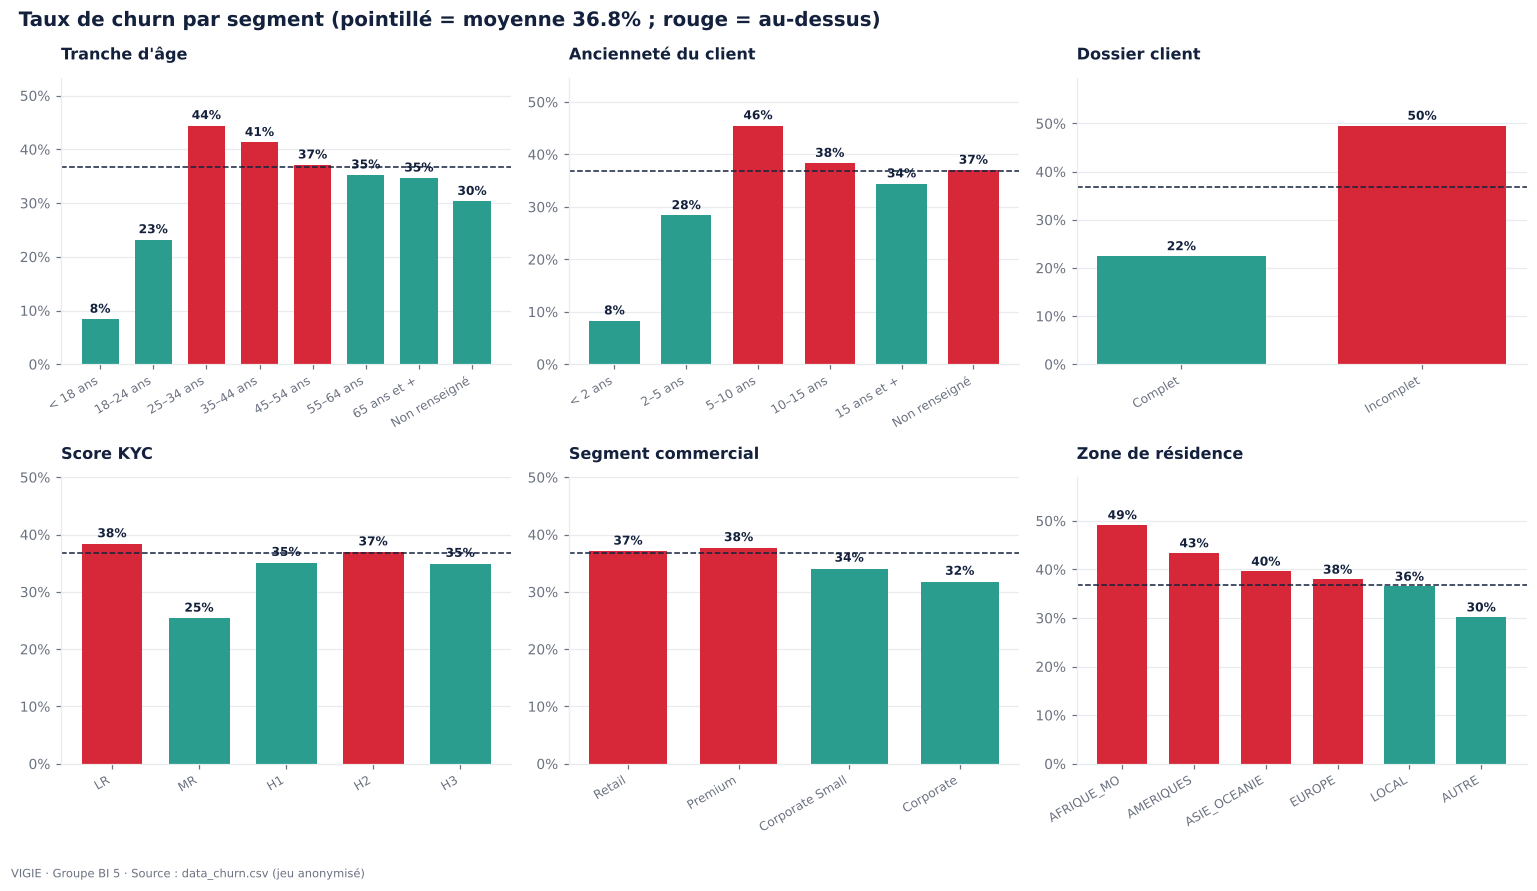

In [3]:
def barres_churn(ax, col, titre, ordre=None, top=None):
    x = base[col].astype("object").where(base[col].notna(), "Non renseigné")
    t = base.groupby(x)["CHURN"].agg(["mean", "size"])
    t = t[t["size"] >= config.SEUIL_PETIT_EFFECTIF]
    t = t.loc[[o for o in ordre if o in t.index]] if ordre else t.sort_values("mean", ascending=False)
    if top:
        t = t.head(top)
    couleurs = [C["churn"] if v > taux_global else C["retention"] for v in t["mean"]]
    ax.bar(range(len(t)), t["mean"], color=couleurs, width=0.7)
    ax.axhline(taux_global, color=C["encre"], ls="--", lw=1)
    for i, (v, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, fontweight="bold", color=C["encre"])
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
    ax.yaxis.set_major_formatter(style.pourcent)
    ax.set_ylim(0, max(t["mean"].max() * 1.2, 0.5))
    ax.set_title(titre, fontsize=10.5)
    ax.grid(axis="x", visible=False)


ordre_age = ["< 18 ans", "18–24 ans", "25–34 ans", "35–44 ans", "45–54 ans", "55–64 ans", "65 ans et +", "Non renseigné"]
ordre_anc = ["< 2 ans", "2–5 ans", "5–10 ans", "10–15 ans", "15 ans et +", "Non renseigné"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.8))
barres_churn(axes[0, 0], "TRANCHE_AGE", "Tranche d'âge", ordre_age)
barres_churn(axes[0, 1], "TRANCHE_ANCIENNETE", "Ancienneté du client", ordre_anc)
barres_churn(axes[0, 2], "DOSSIER_COMPLET", "Dossier client", ["Complet", "Incomplet"])
barres_churn(axes[1, 0], "SCORE_KYC", "Score KYC", ["LR", "MR", "H1", "H2", "H3"])
barres_churn(axes[1, 1], "PARTYCLASS", "Segment commercial", ["Retail", "Premium", "Corporate Small", "Corporate"])
barres_churn(axes[1, 2], "RESIDENCE_REGION", "Zone de résidence")
fig.suptitle(f"Taux de churn par segment (pointillé = moyenne {taux_global:.1%} ; rouge = au-dessus)", x=0.01, ha="left",
             fontweight="bold", color=C["encre"], fontsize=13)
fig.tight_layout()
style.enregistrer(fig, "02_bivarie_qualitatif")
plt.show()

In [4]:
for col, ordre in [("TRANCHE_AGE", ordre_age), ("TRANCHE_ANCIENNETE", ordre_anc), ("DOSSIER_COMPLET", None), ("SCORE_KYC", None)]:
    t = base.groupby(col)["CHURN"].agg(Clients="size", Taux_de_churn="mean")
    if ordre:
        t = t.loc[[o for o in ordre if o in t.index]]
    t["Taux_de_churn"] = t["Taux_de_churn"].map("{:.1%}".format)
    display(t)

,Clients,Taux_de_churn
TRANCHE_AGE,,
< 18 ans,10067,8.4%
18–24 ans,9054,23.2%
25–34 ans,52602,44.4%
35–44 ans,66685,41.3%
45–54 ans,60413,37.1%
55–64 ans,47878,35.2%
65 ans et +,52315,34.7%
Non renseigné,20026,30.3%


,Clients,Taux_de_churn
TRANCHE_ANCIENNETE,,
< 2 ans,8478,8.3%
2–5 ans,48508,28.4%
5–10 ans,91424,45.5%
10–15 ans,63124,38.3%
15 ans et +,105653,34.4%
Non renseigné,1853,37.0%


,Clients,Taux_de_churn
DOSSIER_COMPLET,,
Complet,150750,22.5%
Incomplet,168290,49.6%


,Clients,Taux_de_churn
SCORE_KYC,,
H1,17170,35.1%
H2,9796,36.9%
H3,4099,34.9%
LR,256284,38.3%
MR,31649,25.3%


**Lecture — variables qualitatives**

* **Dossier client** : c'est la variable qualitative la plus liée au churn (V = 0,28). Un client au dossier
  **incomplet** part plus de deux fois plus souvent (49,6 %) qu'un client au dossier complet (22,5 %).
* **Âge** et **ancienneté** : le lien existe (V ≈ 0,15) mais il n'est **pas monotone**. Le churn culmine chez les
  25–34 ans (44 %) et entre 5 et 10 ans d'ancienneté (45,5 %), puis redescend. Les mineurs (8 %) et les clients
  de moins de 2 ans (8 %) partent très peu — pour ces derniers, c'est aussi qu'ils n'ont pas encore eu le temps de partir.
* **Score KYC** : seul le risque moyen `MR` se distingue (25 % contre 35–38 % pour les autres).
* **Groupe d'agences** : écart de 32 % à 46 % selon le groupe — un axe utile pour le pilotage.
* **Segment, ligne métier, nature, secteur** : lien très faible (V ≤ 0,03). Le churn touche tous les segments
  de façon comparable.

## 2. Variables quantitatives × churn

L'**AUC univariée** se lit ainsi : c'est la probabilité qu'un client parti ait une valeur plus élevée qu'un client
resté. 0,5 = aucun pouvoir de séparation ; plus on s'éloigne de 0,5, plus la variable sépare les deux groupes.

In [5]:
quantitatives = {
    "MOIS_DEPUIS_REVUE": "Mois depuis la dernière revue", "MOIS_AVANT_PROCHAINE_REVUE": "Mois avant la prochaine revue",
    "ANCIENNETE_CLIENT": "Ancienneté client (années)", "AGE": "Âge", "NB_COMPTES": "Nombre de comptes",
    "SALARY": "Revenu déclaré",
}
lignes = []
for col, lib in quantitatives.items():
    s = base[[col, "CHURN"]].dropna()
    parti, reste = s.loc[s["CHURN"] == 1, col], s.loc[s["CHURN"] == 0, col]
    _, p = stats.mannwhitneyu(parti, reste)
    lignes.append({
        "Variable": lib, "Clients renseignés": len(s),
        "Médiane — restés": round(reste.median(), 1), "Médiane — partis": round(parti.median(), 1),
        "AUC univariée": round(roc_auc_score(s["CHURN"], s[col]), 3),
        "ρ de Spearman": round(stats.spearmanr(s[col], s["CHURN"])[0], 3),
        "p-value Mann-Whitney": f"{p:.1e}",
    })
liens_quanti = pd.DataFrame(lignes).set_index("Variable")
liens_quanti["Écart à 0,5"] = (liens_quanti["AUC univariée"] - 0.5).abs()
liens_quanti = liens_quanti.sort_values("Écart à 0,5", ascending=False).drop(columns="Écart à 0,5")
display(liens_quanti)

,Clients renseignés,Médiane — restés,Médiane — partis,AUC univariée,ρ de Spearman,p-value Mann-Whitney
Variable,,,,,,
Mois depuis la dernière revue,319015,36.6,60.6,0.672,0.288,0.0e+00
Mois avant la prochaine revue,318980,8.4,-14.6,0.334,-0.277,0.0e+00
Revenu déclaré,104322,400.0,400.0,0.475,-0.045,5.2e-48
Nombre de comptes,319040,1.0,1.0,0.476,-0.066,1.5e-307
Âge,299014,47.0,47.0,0.492,-0.014,1.5e-13
Ancienneté client (années),317187,11.1,10.4,0.505,0.009,6.1e-07


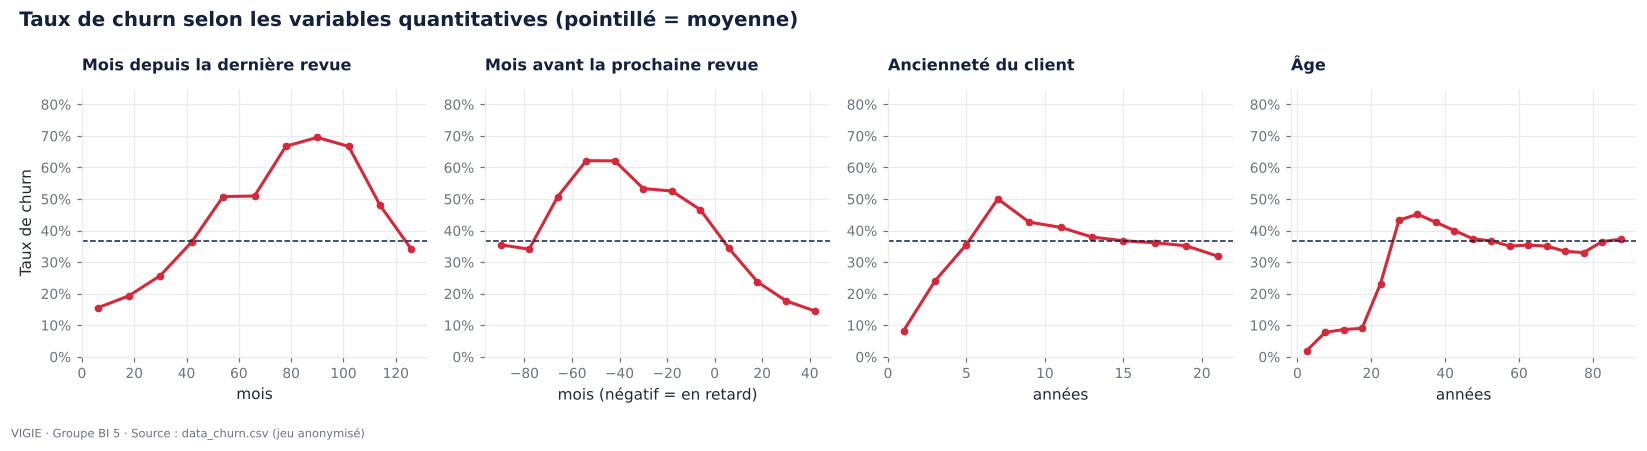

In [6]:
def courbe_churn(ax, col, titre, bornes, unite=""):
    """Taux de churn par tranche d'une variable quantitative."""
    tranche = pd.cut(base[col], bins=bornes)
    t = base.groupby(tranche, observed=True)["CHURN"].agg(["mean", "size"])
    t = t[t["size"] >= config.SEUIL_PETIT_EFFECTIF]
    x = [i.mid for i in t.index]
    ax.plot(x, t["mean"], color=C["churn"], marker="o", lw=2, ms=4)
    ax.axhline(taux_global, color=C["encre"], ls="--", lw=1)
    ax.yaxis.set_major_formatter(style.pourcent)
    ax.set_ylim(0, 0.85)
    ax.set_title(titre, fontsize=10.5)
    ax.set_xlabel(unite)


fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
courbe_churn(axes[0], "MOIS_DEPUIS_REVUE", "Mois depuis la dernière revue", list(range(0, 133, 12)), "mois")
courbe_churn(axes[1], "MOIS_AVANT_PROCHAINE_REVUE", "Mois avant la prochaine revue", list(range(-96, 61, 12)), "mois (négatif = en retard)")
courbe_churn(axes[2], "ANCIENNETE_CLIENT", "Ancienneté du client", list(range(0, 26, 2)), "années")
courbe_churn(axes[3], "AGE", "Âge", list(range(0, 91, 5)), "années")
axes[0].set_ylabel("Taux de churn")
fig.suptitle("Taux de churn selon les variables quantitatives (pointillé = moyenne)", x=0.01, ha="left",
             fontweight="bold", color=C["encre"], fontsize=13)
fig.tight_layout()
style.enregistrer(fig, "02_bivarie_quantitatif")
plt.show()

In [7]:
t = base.groupby(base["NB_COMPTES"].clip(upper=5))["CHURN"].agg(Clients="size", Taux_de_churn="mean")
t.index = [str(i) if i < 5 else "5 et +" for i in t.index]
t.index.name = "Nombre de comptes"
t["Taux_de_churn"] = t["Taux_de_churn"].map("{:.1%}".format)
display(t)

,Clients,Taux_de_churn
Nombre de comptes,,
1,273575,38.1%
2,27189,29.8%
3,8623,23.8%
4,4328,24.2%
5 et +,5325,36.6%


**Lecture — variables quantitatives**

* **Revues de dossier** : ce sont les variables les plus séparatrices. Chez les clients partis, la dernière revue
  date en médiane de **61 mois** (37 mois chez les clients restés) et la prochaine revue est **en retard de
  15 mois** (alors qu'elle est à venir dans 8 mois chez les clients restés). Le taux de churn grimpe nettement
  dès que la revue est en retard.
* **Âge et ancienneté** : leur AUC est proche de 0,5 alors que les tranches de la section 1 montrent un vrai effet.
  Ce n'est pas contradictoire : l'effet est **en cloche**, donc invisible pour une mesure monotone. Conséquence
  pratique : un modèle linéaire les exploitera mal, un modèle à base d'arbres les exploitera bien.
* **Nombre de comptes** : le multi-équipement protège. 38 % de churn avec un seul compte, 24 % avec trois ou quatre.
* **Revenu déclaré** : lien très faible, et la variable est vide pour deux clients sur trois.

⚠ **Prudence d'interprétation.** Un dossier non revu ou incomplet peut être une *cause* du départ (client délaissé)
mais aussi une *conséquence* (on ne revoit plus le dossier d'un client parti). Ces variables de conformité sont
donc conservées, mais leur poids est mesuré à part dans la phase 4 (analyse de sensibilité « avec / sans »).

## 3. Corrélations entre variables quantitatives

Corrélation de **Spearman** (rangs) : adaptée à des variables arrondies et asymétriques.

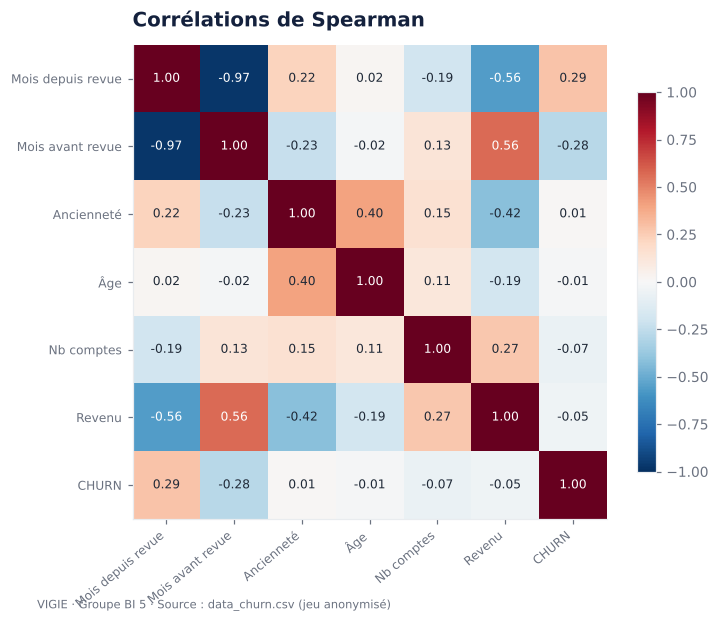

In [8]:
cols = list(quantitatives) + ["CHURN"]
noms = ["Mois depuis revue", "Mois avant revue", "Ancienneté", "Âge", "Nb comptes", "Revenu", "CHURN"]
corr = base[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(noms)))
ax.set_yticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=40, ha="right", fontsize=8)
ax.set_yticklabels(noms, fontsize=8)
for i in range(len(noms)):
    for j in range(len(noms)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else C["texte"])
ax.grid(False)
ax.set_title("Corrélations de Spearman")
fig.colorbar(im, ax=ax, shrink=0.8)
style.enregistrer(fig, "02_bivarie_correlations")
plt.show()

Les deux variables de revue sont fortement et négativement corrélées entre elles : elles racontent la même
histoire (un dossier revu il y a longtemps a une prochaine revue en retard). Les autres variables sont
peu corrélées entre elles : elles apportent des informations complémentaires.

## 4. Redondances entre variables qualitatives

Deux variables très liées entre elles apportent la même information : on n'en gardera qu'une en modélisation.

In [9]:
paires = [("PARTYCLASS", "LOB"), ("RESIDENCE_REGION", "NATIONALITY_REGION"), ("NATURE_CLIENT", "PARTYCLASS"),
          ("NATURE_CLIENT", "INDUSTRY"), ("SCORE_KYC", "NATURE_CLIENT")]
red = pd.DataFrame([{"Variable A": a, "Variable B": b, "V de Cramér": round(cramers_v(base[a].fillna("NR"), base[b].fillna("NR"))[0], 3)}
                    for a, b in paires])
display(red)

,Variable A,Variable B,V de Cramér
0,PARTYCLASS,LOB,1.000
1,RESIDENCE_REGION,NATIONALITY_REGION,0.708
2,NATURE_CLIENT,PARTYCLASS,0.524
3,NATURE_CLIENT,INDUSTRY,0.580
4,SCORE_KYC,NATURE_CLIENT,0.400


`PARTYCLASS` et `LOB` sont **strictement équivalentes** (V = 1,00) : on ne garde que le segment commercial.
Zones de résidence et de nationalité sont très liées (V = 0,71) : on ne garde que la résidence.

## 5. Et les variables du compte ? Un piège à éviter

On pourrait croiser le churn avec la famille de compte, la devise ou le solde. Mais ces colonnes sont **vides
pour deux comptes clos sur trois** et jamais pour les comptes actifs : leur simple présence renseigne sur la cible.

In [10]:
piege = comptes.assign(INFO_COMPTE=np.where(comptes["ACCT_BALANCE"].isna(), "Solde vide", "Solde renseigné"))
t = piege.groupby("INFO_COMPTE")["CHURN"].agg(Comptes="size", Taux_de_churn="mean")
t["Taux_de_churn"] = t["Taux_de_churn"].map("{:.1%}".format)
display(t)
v_fuite, _ = cramers_v(piege["INFO_COMPTE"], piege["CHURN"])
print(f"V de Cramér entre « solde vide » et churn : {v_fuite:.3f}  (à comparer aux valeurs du tableau de la section 1)")

,Comptes,Taux_de_churn
INFO_COMPTE,,
Solde renseigné,309831,15.4%
Solde vide,100478,100.0%


V de Cramér entre « solde vide » et churn : 0.757  (à comparer aux valeurs du tableau de la section 1)


Un compte dont le solde est vide est **toujours** clos. Le lien (V = 0,76) est sans commune mesure avec celui des
vraies variables explicatives : c'est la signature d'une **fuite de cible**, pas d'un facteur de churn.
Ces colonnes sont exclues de la modélisation (phase 4).

## Synthèse

Classement de toutes les variables par intensité du lien avec le churn. Les deux mesures sont sur la même
échelle de 0 (aucun lien) à 1 (lien parfait).

In [11]:
resume = pd.concat([
    liens_quali[["V de Cramér"]].rename(columns={"V de Cramér": "Intensité"}).assign(Mesure="V de Cramér"),
    (liens_quanti["AUC univariée"] - 0.5).abs().mul(2).round(3).to_frame("Intensité").assign(Mesure="|2·AUC − 1|"),
]).sort_values("Intensité", ascending=False)
display(resume)

,Intensité,Mesure
Variable,,
Mois depuis la dernière revue,0.344,|2·AUC − 1|
Mois avant la prochaine revue,0.332,|2·AUC − 1|
Dossier complet,0.280,V de Cramér
Tranche d'ancienneté,0.156,V de Cramér
Tranche d'âge,0.144,V de Cramér
Score KYC,0.081,V de Cramér
Groupe d'agences,0.065,V de Cramér
Revenu déclaré,0.050,|2·AUC − 1|
Nombre de comptes,0.048,|2·AUC − 1|


**À retenir pour la suite**

1. Les variables de **conformité** (revue du dossier, dossier complet) sont de loin les plus liées au churn.
2. L'**âge** et l'**ancienneté** ont un effet en cloche : il faut des modèles capables de capter le non-linéaire.
3. Le **multi-équipement** protège : les clients à un seul compte sont les plus fragiles.
4. Le **segment commercial** et le **secteur** discriminent très peu.
5. Les colonnes du compte (solde, famille, devise…) sont une **fuite de cible** et ne sont pas des variables explicatives.